# Figure 3 — Large-Batch Training Reproduction (Phase 4)

Run the three plotting cells in order. Reads **only recorded interpolation results** from `results/paper2/final_61/` (F1, Phase 3) and `results/paper2/phase4_author_aligned/` (C1/C2, Phase 4). All figures appear **inline**; no files or directories are created. Each panel displays cross-entropy (blue, left axis) and classification accuracy (red, right axis): solid lines indicate training data and dashed lines testing data. The α interval is [−1, 2], with **α = 0** the small-batch solution and **α = 1** the large-batch solution.

The plotted values were measured by `src/interpolate.py` / `src/phase4_interpolate.py`, not hardcoded or fitted to the published figure. These 61-point runs use recalibrated BatchNorm statistics (4,096 training examples per interpolation point). Phase 4 uses the author's released C1 stride-1 architecture and C2 dropout placements, with FP16 mixed-precision training on a Tesla T4; it is not an exact reproduction of the paper's numerical setup. This notebook does not retrain or re-evaluate the networks.

## Figure 3(a) — F1 (fully connected, MNIST)

Five 512-unit hidden layers with batch normalization and ReLU. **F1 is unchanged from Phase 3**; the original recorded F1 interpolation is reused.

Phase 3 F1: C:\Users\ASUS\Documents\GitHub\advanced-ml-paper-reproductions\paper2-large-batch\results\paper2\final_61
Phase 4 C1/C2: C:\Users\ASUS\Documents\GitHub\advanced-ml-paper-reproductions\paper2-large-batch\results\paper2\phase4_author_aligned
F1: 61 measured points; BN policy=recalibrate; BN examples=4096
  SB (alpha=0): train CE=0.00588, train accuracy=99.82%, test accuracy=98.15%
  LB (alpha=1): train CE=0.00017, train accuracy=100.00%, test accuracy=98.38%


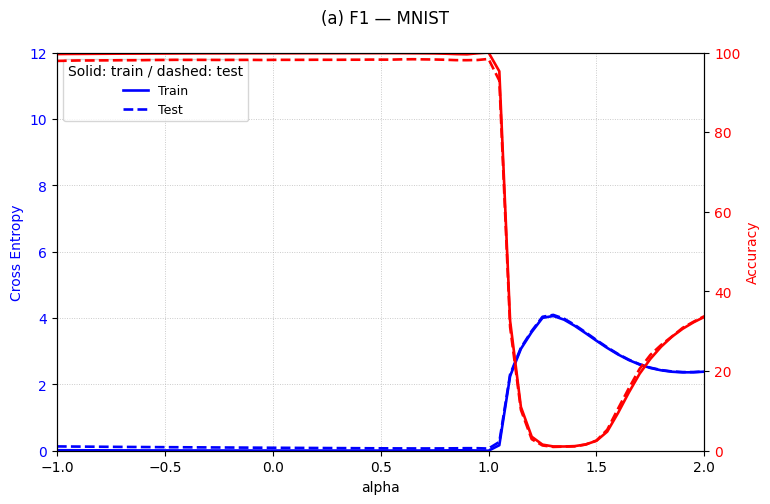

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Optional: set this to the paper2-large-batch directory if using a different working directory.
PROJECT_ROOT = None

def find_project():
    if PROJECT_ROOT is not None:
        root = Path(PROJECT_ROOT).expanduser().resolve()
        if not root.is_dir():
            raise FileNotFoundError(root)
        return root
    here = Path.cwd().resolve()
    candidates = [here, here.parent, here / 'paper2-large-batch',
                  here.parent / 'paper2-large-batch']
    for root in candidates:
        if (root / 'results' / 'paper2' / 'final_61' / 'F1_interpolation.json').is_file():
            return root
    raise FileNotFoundError('Could not locate paper2-large-batch. Set PROJECT_ROOT above.')

project = find_project()
phase3 = project / 'results' / 'paper2' / 'final_61'
phase4 = project / 'results' / 'paper2' / 'phase4_author_aligned'
print('Phase 3 F1:', phase3)
print('Phase 4 C1/C2:', phase4)

PANEL_LABELS = {'F1': 'a', 'C1': 'c', 'C2': 'd'}
PANEL_DATASETS = {'F1': 'MNIST', 'C1': 'CIFAR-10', 'C2': 'CIFAR-10'}
# Presentation-only reference y-axis maxima; measured data are never clipped.
PAPER_LOSS_MAX = {'F1': 12, 'C1': 8, 'C2': 7}

def load_panel(panel):
    source = (phase3 if panel == 'F1' else phase4) / f'{panel}_interpolation.json'
    if not source.is_file():
        raise FileNotFoundError(source)
    data = json.loads(source.read_text(encoding='utf-8'))
    if data.get('panel') != panel:
        raise ValueError(f'Incorrect panel metadata in {source}')
    if data.get('bn_policy') != 'recalibrate':
        raise ValueError(f'{panel}: expected recalibrated BatchNorm; got {data.get("bn_policy")}')
    points = sorted(data['points'], key=lambda p: p['alpha'])
    alpha = np.array([p['alpha'] for p in points], dtype=float)
    if len(points) != 61 or not np.allclose(alpha, np.linspace(-1, 2, 61)):
        raise ValueError(f'{panel}: expected 61 measured points from -1 to 2')
    series = {}
    for key in ('train_loss', 'test_loss', 'train_accuracy', 'test_accuracy'):
        values = np.array([p[key] for p in points], dtype=float)
        if not np.isfinite(values).all():
            raise ValueError(f'{panel}: non-finite {key} values')
        series[key] = values
    for key in ('train_accuracy', 'test_accuracy'):
        if np.any((series[key] < 0) | (series[key] > 1)):
            raise ValueError(f'{panel}: invalid accuracy range')
    return alpha, series, data

def plot_panel(panel):
    alpha, values, metadata = load_panel(panel)
    fig, loss_ax = plt.subplots(figsize=(7.8, 5.1))
    acc_ax = loss_ax.twinx()
    for split, line in (('train', '-'), ('test', '--')):
        loss_ax.plot(alpha, values[f'{split}_loss'], color='blue',
                     linestyle=line, linewidth=1.9, label=split.title())
        acc_ax.plot(alpha, 100 * values[f'{split}_accuracy'], color='red',
                    linestyle=line, linewidth=1.9)
    max_loss = max(values['train_loss'].max(), values['test_loss'].max())
    loss_ax.set_ylim(0, max(PAPER_LOSS_MAX[panel], float(max_loss) * 1.06))
    loss_ax.set_xlim(-1, 2)
    acc_ax.set_ylim(0, 100)
    loss_ax.set_xticks(np.arange(-1, 2.01, .5))
    loss_ax.set(xlabel='alpha', ylabel='Cross Entropy')
    acc_ax.set_ylabel('Accuracy')
    loss_ax.yaxis.label.set_color('blue')
    acc_ax.yaxis.label.set_color('red')
    loss_ax.tick_params(axis='y', labelcolor='blue')
    acc_ax.tick_params(axis='y', labelcolor='red')
    loss_ax.grid(linestyle=':', linewidth=.65, alpha=.75)
    loss_ax.legend(loc='upper left', title='Solid: train / dashed: test', fontsize=9)
    fig.suptitle(f'({PANEL_LABELS[panel]}) {panel} — {PANEL_DATASETS[panel]}', fontsize=12)
    fig.tight_layout()
    print(f'{panel}: {len(alpha)} measured points; BN policy={metadata["bn_policy"]}; '
          f'BN examples={metadata["bn_examples"]}')
    for regime, target in (('SB', 0.0), ('LB', 1.0)):
        ix = np.flatnonzero(np.isclose(alpha, target, atol=1e-12))
        assert len(ix) == 1
        i = int(ix[0])
        print(f'  {regime} (alpha={target:g}): '
              f'train CE={values["train_loss"][i]:.5f}, '
              f'train accuracy={100*values["train_accuracy"][i]:.2f}%, '
              f'test accuracy={100*values["test_accuracy"][i]:.2f}%')
    display(fig)
    plt.close(fig)

plot_panel('F1')

## Figure 3(c) — C1 (shallow convolutional, CIFAR-10)

Two stride-1 convolution/pooling stages followed by a 384–192-unit classifier, following the first author's released `shallownet()` architecture. **Phase 4 uses FP16 training**; the figure uses the recorded 61-point interpolation measurements.

C1: 61 measured points; BN policy=recalibrate; BN examples=4096
  SB (alpha=0): train CE=0.00340, train accuracy=99.93%, test accuracy=80.29%
  LB (alpha=1): train CE=0.01233, train accuracy=99.82%, test accuracy=76.64%


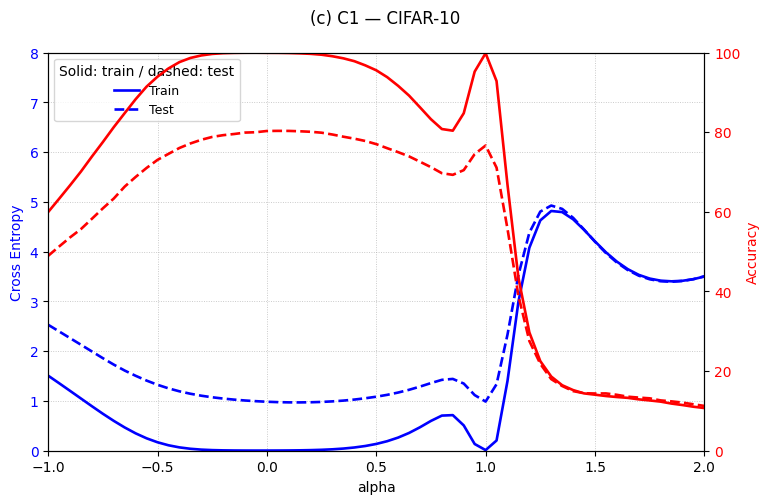

In [2]:
plot_panel('C1')

## Figure 3(d) — C2 (deep convolutional, CIFAR-10)

VGG-like five-stage convolutional network with the first author's convolutional and dense dropout placements. **Phase 4 uses FP16 training**; the figure uses the recorded 61-point interpolation measurements.

C2: 61 measured points; BN policy=recalibrate; BN examples=4096
  SB (alpha=0): train CE=0.00966, train accuracy=99.80%, test accuracy=88.56%
  LB (alpha=1): train CE=0.09223, train accuracy=97.09%, test accuracy=86.12%


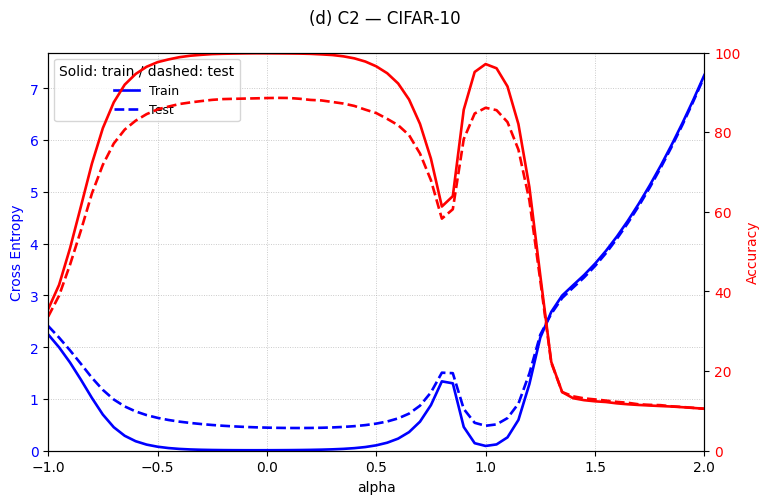

In [3]:
plot_panel('C2')